# Tasks for laboratory assignment 3

In [1]:
# imports section

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, classification_report,
                             f1_score, mean_absolute_error, r2_score, roc_auc_score, root_mean_squared_error)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, TimeSeriesSplit, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42
FIGURES_DIR = Path('figures') / 'assignment-3'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')

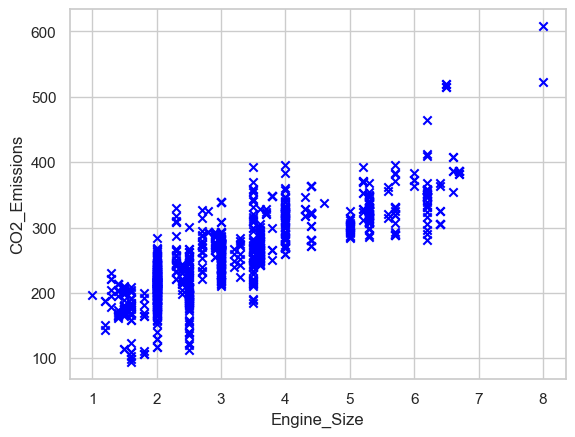

In [2]:
def build_plot(file_path, x, y):
    data = pd.read_csv(file_path)
    plt.scatter(data[x], data[y], c='blue', marker='x')
    plt.xlabel(x)
    plt.ylabel(y)
    return plt

build_plot('resources/CO2_emission.csv', 'Engine_Size', 'CO2_Emissions').show()

In [3]:
def extract_texts_from_file(file_path):
    """
    Extract the text data from the csv file

    Args:
        file_path (str): Relative location of the csv file in the project.

    Returns:
        pd.DataFrame: The file contents as a DataFrame.
    """
    return pd.read_csv(file_path)

data = extract_texts_from_file('resources/heart.csv')
print(data[:50])

    age  sex  cp  trtbps  chol  fbs  restecg  thalachh  exng  oldpeak  slp  \
0    63    1   3     145   233    1        0       150     0      2.3    0   
1    37    1   2     130   250    0        1       187     0      3.5    0   
2    41    0   1     130   204    0        0       172     0      1.4    2   
3    56    1   1     120   236    0        1       178     0      0.8    2   
4    57    0   0     120   354    0        1       163     1      0.6    2   
5    57    1   0     140   192    0        1       148     0      0.4    1   
6    56    0   1     140   294    0        0       153     0      1.3    1   
7    44    1   1     120   263    0        1       173     0      0.0    2   
8    52    1   2     172   199    1        1       162     0      0.5    2   
9    57    1   2     150   168    0        1       174     0      1.6    2   
10   54    1   0     140   239    0        1       160     0      1.2    2   
11   48    0   2     130   275    0        1       139     0    

## Shared helpers

In [4]:
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / name, dpi=120, bbox_inches='tight')
    plt.show()


def polynomial_model(degree):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False), StandardScaler(), LinearRegression())


def select_polynomial_degree(X, y, max_degree=5, cv=None):
    """
    Choose the polynomial degree by cross-validated RMSE using the one-standard-error rule:
    the simplest degree whose CV RMSE is within one standard error of the best one.
    This avoids picking a wiggly high-degree curve for a negligible gain.
    """
    cv = cv or KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    scores, errors = {}, {}
    for degree in range(1, max_degree + 1):
        rmse = -cross_val_score(polynomial_model(degree), X, y, cv=cv, scoring='neg_root_mean_squared_error')
        scores[degree] = float(rmse.mean())
        errors[degree] = float(rmse.std(ddof=1) / np.sqrt(len(rmse)))
    best = min(scores, key=scores.get)
    degree = min(d for d in scores if scores[d] <= scores[best] + errors[best])
    return degree, scores


def report_regression(y_true, y_pred):
    print(f'Test R2:   {r2_score(y_true, y_pred):.3f}')
    print(f'Test RMSE: {root_mean_squared_error(y_true, y_pred):.3f}')
    print(f'Test MAE:  {mean_absolute_error(y_true, y_pred):.3f}')


def model_theta(model):
    """[intercept, *coefficients] of the final linear step of a pipeline."""
    estimator = model[-1]
    return [float(np.ravel(estimator.intercept_)[0]), *map(float, np.ravel(estimator.coef_))]


def fit_polynomial_regression(df, feature, target, max_degree=5, file_name=None):
    """
    Fit y = poly(x) choosing the degree by 5-fold CV on the training set,
    then report the hold-out test metrics and plot the fitted curve.
    """
    X, y = df[[feature]], df[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

    degree, cv_scores = select_polynomial_degree(X_train, y_train, max_degree)
    model = polynomial_model(degree).fit(X_train, y_train)
    print('CV RMSE by degree:', {d: round(s, 3) for d, s in cv_scores.items()})
    print(f'Selected degree: {degree}')
    report_regression(y_test, model.predict(X_test))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [2, 1]})
    ax1.scatter(X_train[feature], y_train, s=15, alpha=0.5, label='train')
    ax1.scatter(X_test[feature], y_test, s=15, alpha=0.8, marker='x', label='test')
    grid = pd.DataFrame({feature: np.linspace(X[feature].min(), X[feature].max(), 300)})
    ax1.plot(grid[feature], model.predict(grid), color='black', lw=2, label=f'polynomial, degree {degree}')
    ax1.set(xlabel=feature, ylabel=target, title=f'{target} vs {feature}')
    ax1.legend()
    ax2.plot(list(cv_scores), list(cv_scores.values()), marker='o')
    ax2.axvline(degree, color='gray', ls='--')
    ax2.set(xlabel='Polynomial degree', ylabel='CV RMSE', title='Model selection')
    save_figure(fig, file_name or f'{target}_regression.png')

    # Coefficients refer to standardized polynomial features.
    return model_theta(model)

## CO2 emissions

Process file `CO2_emission.csv`. Build a model, that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

CV RMSE by degree: {1: 35.989, 2: 36.183, 3: 35.616, 4: 36.221, 5: 42.182}
Selected degree: 1
Test R2:   0.642
Test RMSE: 37.973
Test MAE:  28.571


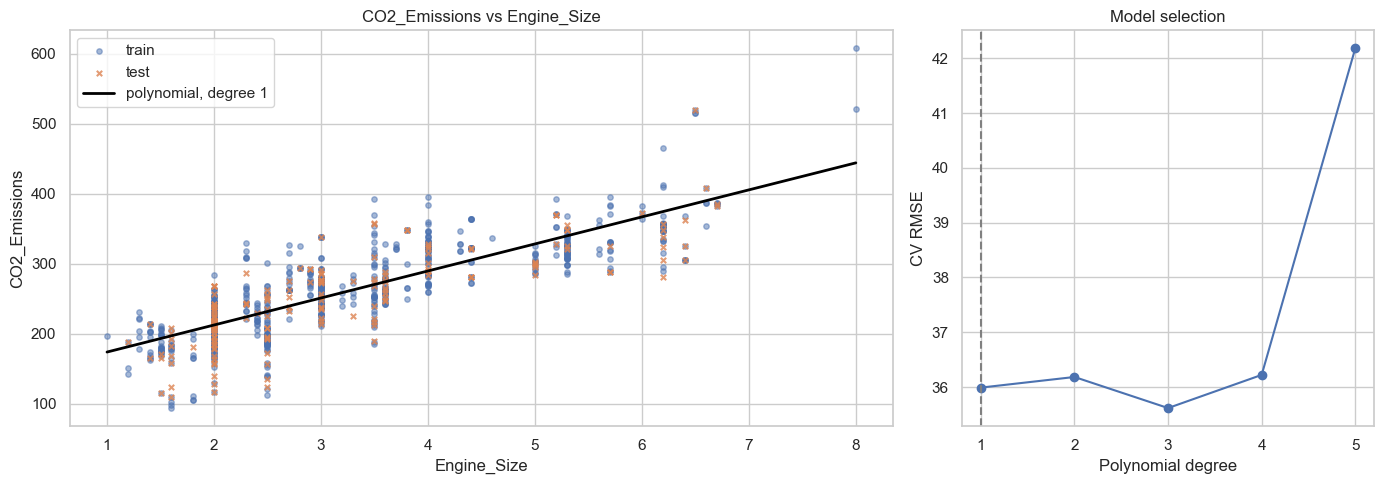

[260.225935828877, 53.601466278884935]

In [5]:
def CO2_emissions(data):
    """
    Build a model that would predict CO2 emissions from the size of the engine of car. Visualize model on a plot.

    Args:
        data: CO2 emissions data.

    Returns:
        list: The list of model theta parameters.
    """
    return fit_polynomial_regression(data, 'Engine_Size', 'CO2_Emissions', file_name='co2_emissions.png')

data = extract_texts_from_file('resources/CO2_emission.csv')
CO2_emissions(data)

## Ice Cream Sales

Process file `ice_cream_selling_data.csv`. Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

CV RMSE by degree: {1: 12.169, 2: 3.157, 3: 3.622, 4: 3.138, 5: 2.671}
Selected degree: 5
Test R2:   0.778
Test RMSE: 4.586
Test MAE:  3.511


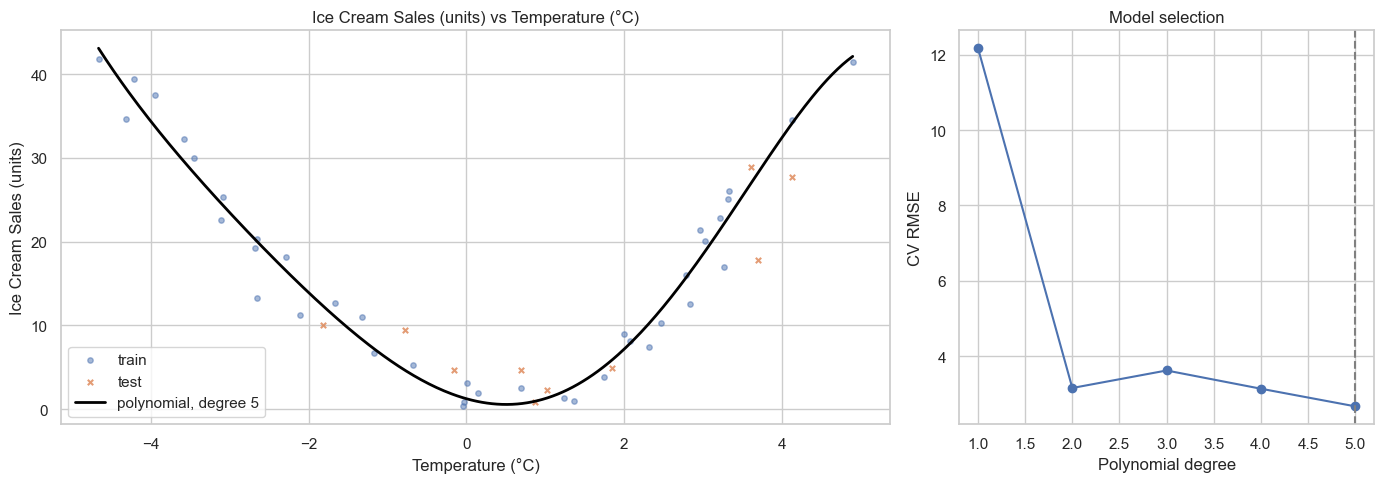

[17.134323592054045,
 -7.349148869400718,
 15.13069331487949,
 10.526436937382584,
 -3.5068154008162917,
 -5.411222146596206]

In [6]:
def ice_cream_selling(data):
    """
    Build a model, that would predict ice cream sales based on the temperature. Visualize model on a plot.

    Args:
        data: ice cream sales data.

    Returns:
        list: The list of model theta parameters.
    """
    return fit_polynomial_regression(data, 'Temperature (°C)', 'Ice Cream Sales (units)', file_name='ice_cream_sales.png')

data = extract_texts_from_file('resources/ice_cream_selling_data.csv')
ice_cream_selling(data)

## Electric Power Consumption

Process file `powerconsumption.csv`. Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed. Visualize model on a plot.

Choose regression model that would best fit the data. Choose the library for model implementation (sklearn, other library, custom implementation).

CV RMSE by degree: {1: 15847.7, 2: 15594.4, 3: 15633.1}
Selected degree: 1
Test R2:   0.086
Test RMSE: 13486.900
Test MAE:  11419.295


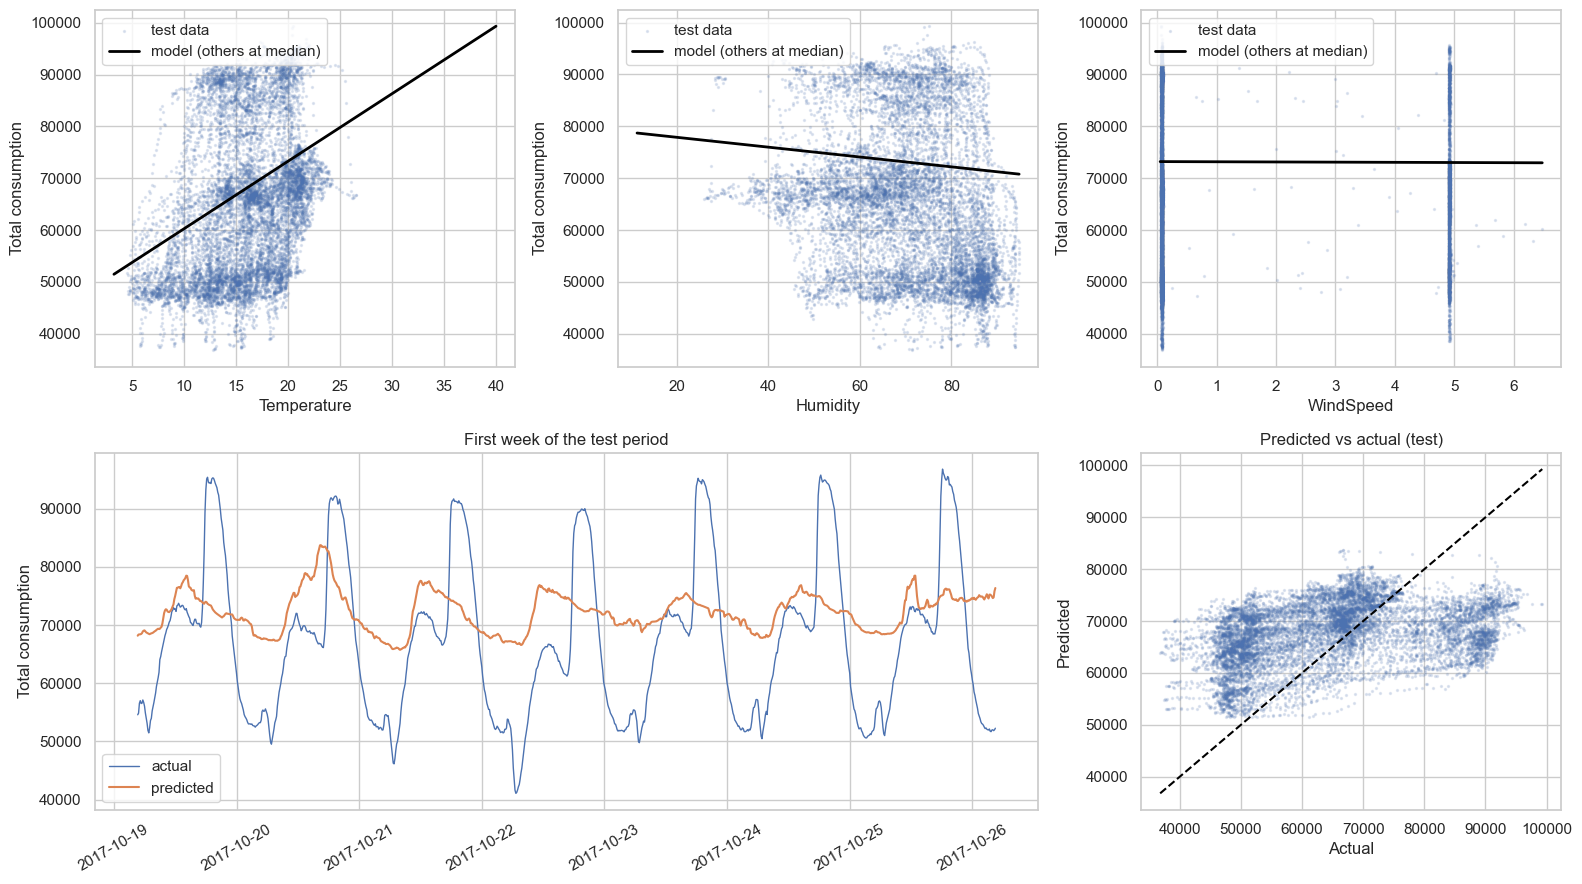

[72814.44221109603, 7743.416065755603, -1525.230328548395, -85.54336546053787]

In [7]:
WEATHER_FEATURES = ['Temperature', 'Humidity', 'WindSpeed']


def power_consumption(data):
    """
    Build a model, that would predict electricity consumption from the weather: temperature, humidity and wind speed.
    Visualize model on a plot.

    Args:
        data: power consumption data.

    Returns:
        list: The list of model theta parameters.
    """
    data = data.assign(Datetime=pd.to_datetime(data['Datetime'], format='%m/%d/%Y %H:%M')).sort_values('Datetime')
    zones = [c for c in data.columns if c.startswith('PowerConsumption_')]
    data['TotalPowerConsumption'] = data[zones].sum(axis=1)

    X, y = data[WEATHER_FEATURES], data['TotalPowerConsumption']
    # Time series: train on the past, test on the future (no shuffling, no leakage).
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

    degree, cv_scores = select_polynomial_degree(X_train, y_train, max_degree=3, cv=TimeSeriesSplit(n_splits=5))
    model = polynomial_model(degree).fit(X_train, y_train)
    print('CV RMSE by degree:', {d: round(s, 1) for d, s in cv_scores.items()})
    print(f'Selected degree: {degree}')
    y_pred = pd.Series(model.predict(X_test), index=y_test.index)
    report_regression(y_test, y_pred)

    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    # Partial effect of each feature: vary it, keep the others at their median.
    for ax, feature in zip(axes[0], WEATHER_FEATURES):
        ax.scatter(X_test[feature], y_test, s=2, alpha=0.15, label='test data')
        grid = pd.DataFrame({f: np.repeat(X_train[f].median(), 200) for f in WEATHER_FEATURES})
        grid[feature] = np.linspace(X[feature].min(), X[feature].max(), 200)
        ax.plot(grid[feature], model.predict(grid), color='black', lw=2, label='model (others at median)')
        ax.set(xlabel=feature, ylabel='Total consumption')
        ax.legend(loc='upper left')

    week = data.loc[y_test.index, 'Datetime'].iloc[:7 * 24 * 6]  # 10-minute readings
    axes[1, 0].remove()
    axes[1, 1].remove()
    ax = fig.add_subplot(2, 3, (4, 5))
    ax.plot(week, y_test.loc[week.index], lw=1, label='actual')
    ax.plot(week, y_pred.loc[week.index], lw=1.5, label='predicted')
    ax.set(title='First week of the test period', ylabel='Total consumption')
    ax.legend()
    ax.tick_params(axis='x', rotation=30)
    axes[1, 2].scatter(y_test, y_pred, s=2, alpha=0.15)
    lims = [y_test.min(), y_test.max()]
    axes[1, 2].plot(lims, lims, color='black', ls='--')
    axes[1, 2].set(xlabel='Actual', ylabel='Predicted', title='Predicted vs actual (test)')
    save_figure(fig, 'power_consumption.png')

    return model_theta(model)

data = extract_texts_from_file('resources/powerconsumption.csv')
power_consumption(data)

## Heart Conditions Predictions

Process file `heart.csv`. It has the following data:

- age - Age of the patient
- sex - Sex of the patient
- cp - Chest pain type ~ 0 = Typical Angina, 1 = Atypical Angina, 2 = Non-anginal Pain, 3 = Asymptomatic
- trtbps - Resting blood pressure (in mm Hg)
- chol - Cholestoral in mg/dl fetched via BMI sensor
- fbs - (fasting blood sugar > 120 mg/dl) ~ 1 = True, 0 = False
- restecg - Resting electrocardiographic results ~ 0 = Normal, 1 = ST-T wave normality, 2 = Left ventricular hypertrophy
- thalachh - Maximum heart rate achieved
- oldpeak - Previous peak
- slp - Slope
- caa - Number of major vessels
- thall - Thalium Stress Test result ~ (0,3)
- exng - Exercise induced angina ~ 1 = Yes, 0 = No
- output - Target variable - risk of heart attack - 1 is high chance of heart attack and 0 is low chance.

Use classification model (choose model best fitting model yourself). Choose parameters that would best fit for making a prediction on. Visualize model on a plot.

Do not forget to split data into train data and validation data. Validate your model.

LogisticRegression   CV ROC AUC = 0.902  {'model__C': 0.1, 'model__l1_ratio': 0.0}


RidgeClassifier      CV ROC AUC = 0.898  {'model__alpha': 100}


SGDClassifier        CV ROC AUC = 0.898  {'model__alpha': 0.1, 'model__l1_ratio': 0.0}

Best model: LogisticRegression
Validation accuracy: 0.869
Validation ROC AUC:  0.907
              precision    recall  f1-score   support

    low risk       0.92      0.79      0.85        28
   high risk       0.84      0.94      0.89        33

    accuracy                           0.87        61
   macro avg       0.88      0.86      0.87        61
weighted avg       0.87      0.87      0.87        61



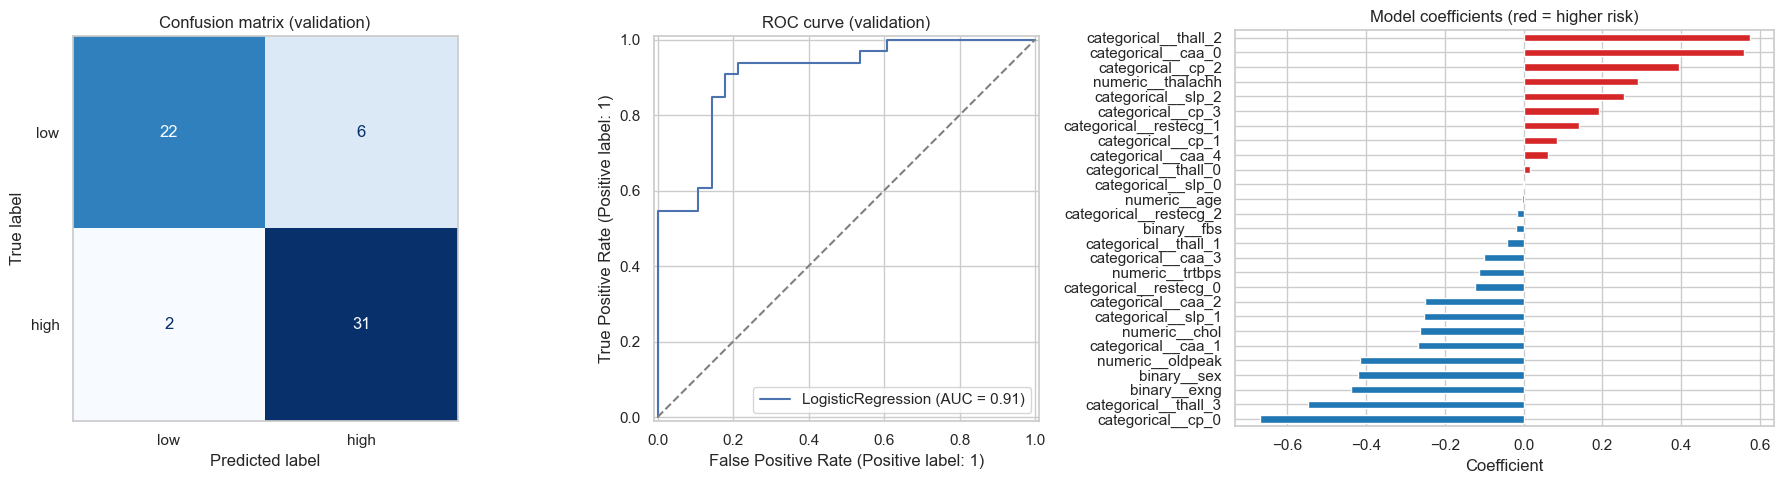

[0.5059774701235135,
 -0.0027162722522572932,
 -0.11291143122140399,
 -0.26383282645120393,
 0.290771063083293,
 -0.4161835514541309,
 -0.6700143021523062,
 0.08503778058617284,
 0.3935571066184175,
 0.192407044809822,
 -0.12318875652050143,
 0.1414161526699188,
 -0.017239766287309412,
 -0.0013153162717169933,
 -0.25299970833442303,
 0.25530265446824607,
 0.5589912066245967,
 -0.2686046781556228,
 -0.250446924121506,
 -0.1000454061830954,
 0.061093431697733534,
 0.015523531869958522,
 -0.04186410572142823,
 0.5734127164263222,
 -0.5460845127127484,
 -0.41939115521443304,
 -0.02019251907682654,
 -0.43907891711783575]

In [8]:
HEART_NUMERIC = ['age', 'trtbps', 'chol', 'thalachh', 'oldpeak']
HEART_CATEGORICAL = ['cp', 'restecg', 'slp', 'caa', 'thall']
HEART_BINARY = ['sex', 'fbs', 'exng']


def heart_preprocessor():
    return ColumnTransformer([
        ('numeric', StandardScaler(), HEART_NUMERIC),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), HEART_CATEGORICAL),
        ('binary', 'passthrough', HEART_BINARY),
    ])


def heart_classification(data):
    """
    Build a model, that would classify risk category for heart attack.
    Visualize model on a plot.

    Args:
        data: heart medical data.

    Returns:
        list: The list of model theta parameters.
    """
    X, y = data.drop(columns='output'), data['output']
    X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

    # l1_ratio > 0 adds L1 regularization, which drops uninformative features (feature selection).
    candidates = {
        'LogisticRegression': (LogisticRegression(solver='saga', max_iter=10_000, random_state=RANDOM_STATE),
                               {'C': [0.01, 0.1, 1, 10], 'l1_ratio': [0.0, 0.5, 1.0]}),
        'RidgeClassifier': (RidgeClassifier(), {'alpha': [0.1, 1, 10, 100]}),
        'SGDClassifier': (SGDClassifier(loss='log_loss', penalty='elasticnet', random_state=RANDOM_STATE),
                          {'alpha': [1e-4, 1e-3, 1e-2, 1e-1], 'l1_ratio': [0.0, 0.5, 1.0]}),
    }
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    searches = {}
    for name, (estimator, grid) in candidates.items():
        pipeline = Pipeline([('preprocess', heart_preprocessor()), ('model', estimator)])
        search = GridSearchCV(pipeline, {f'model__{k}': v for k, v in grid.items()}, cv=cv, scoring='roc_auc')
        searches[name] = search.fit(X_train, y_train)
        print(f'{name:<20} CV ROC AUC = {search.best_score_:.3f}  {search.best_params_}')

    best_name = max(searches, key=lambda n: searches[n].best_score_)
    model = searches[best_name].best_estimator_
    y_pred = model.predict(X_val)
    print(f'\nBest model: {best_name}')
    print(f'Validation accuracy: {accuracy_score(y_val, y_pred):.3f}')
    print(f'Validation ROC AUC:  {roc_auc_score(y_val, model.decision_function(X_val)):.3f}')
    print(classification_report(y_val, y_pred, target_names=['low risk', 'high risk']))

    feature_names = model[:-1].get_feature_names_out()
    coefficients = pd.Series(np.ravel(model[-1].coef_), index=feature_names).sort_values()

    fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1, 1.4]})
    ConfusionMatrixDisplay.from_estimator(model, X_val, y_val, display_labels=['low', 'high'], cmap='Blues', ax=axes[0], colorbar=False)
    axes[0].set_title('Confusion matrix (validation)')
    axes[0].grid(False)
    RocCurveDisplay.from_estimator(model, X_val, y_val, ax=axes[1], name=best_name)
    axes[1].plot([0, 1], [0, 1], color='gray', ls='--')
    axes[1].set_title('ROC curve (validation)')
    coefficients.plot.barh(ax=axes[2], color=np.where(coefficients > 0, 'tab:red', 'tab:blue'))
    axes[2].set(title='Model coefficients (red = higher risk)', xlabel='Coefficient')
    save_figure(fig, 'heart_classification.png')

    return model_theta(model)

data = extract_texts_from_file('resources/heart.csv')
heart_classification(data)

## Additional (extra credit)

There are more files in the resources folder. Take a look at the. Visualize data in these files. Choose ML algorithm for building a model and making predictions for new data. Visualize the model.

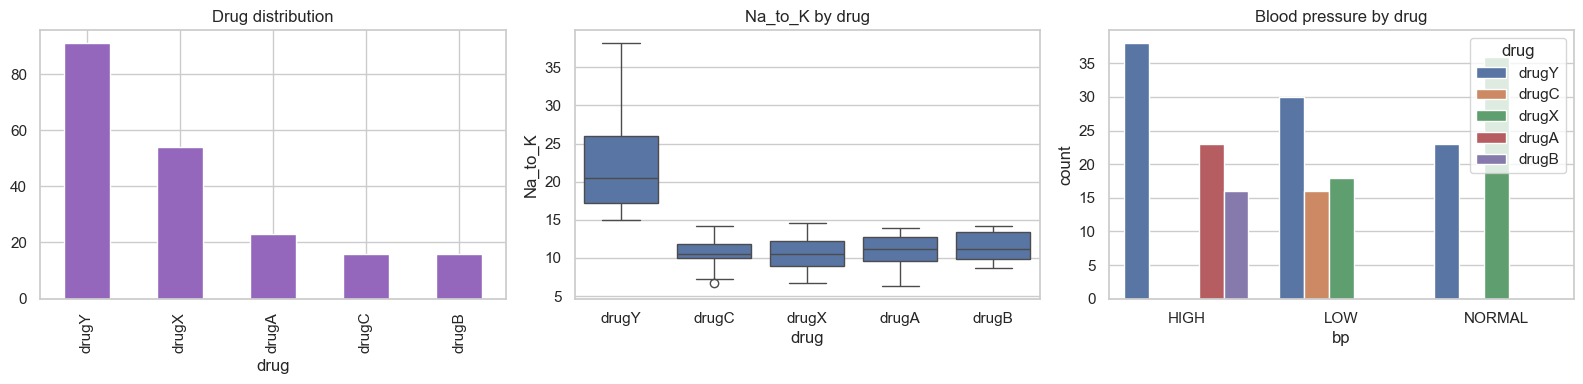

Best params: {'model__max_depth': 4, 'model__min_samples_leaf': 1}, CV macro F1 = 1.000
              precision    recall  f1-score   support

       drugA       0.83      1.00      0.91         5
       drugB       1.00      0.67      0.80         3
       drugC       1.00      1.00      1.00         3
       drugX       1.00      1.00      1.00        11
       drugY       1.00      1.00      1.00        18

    accuracy                           0.97        40
   macro avg       0.97      0.93      0.94        40
weighted avg       0.98      0.97      0.97        40



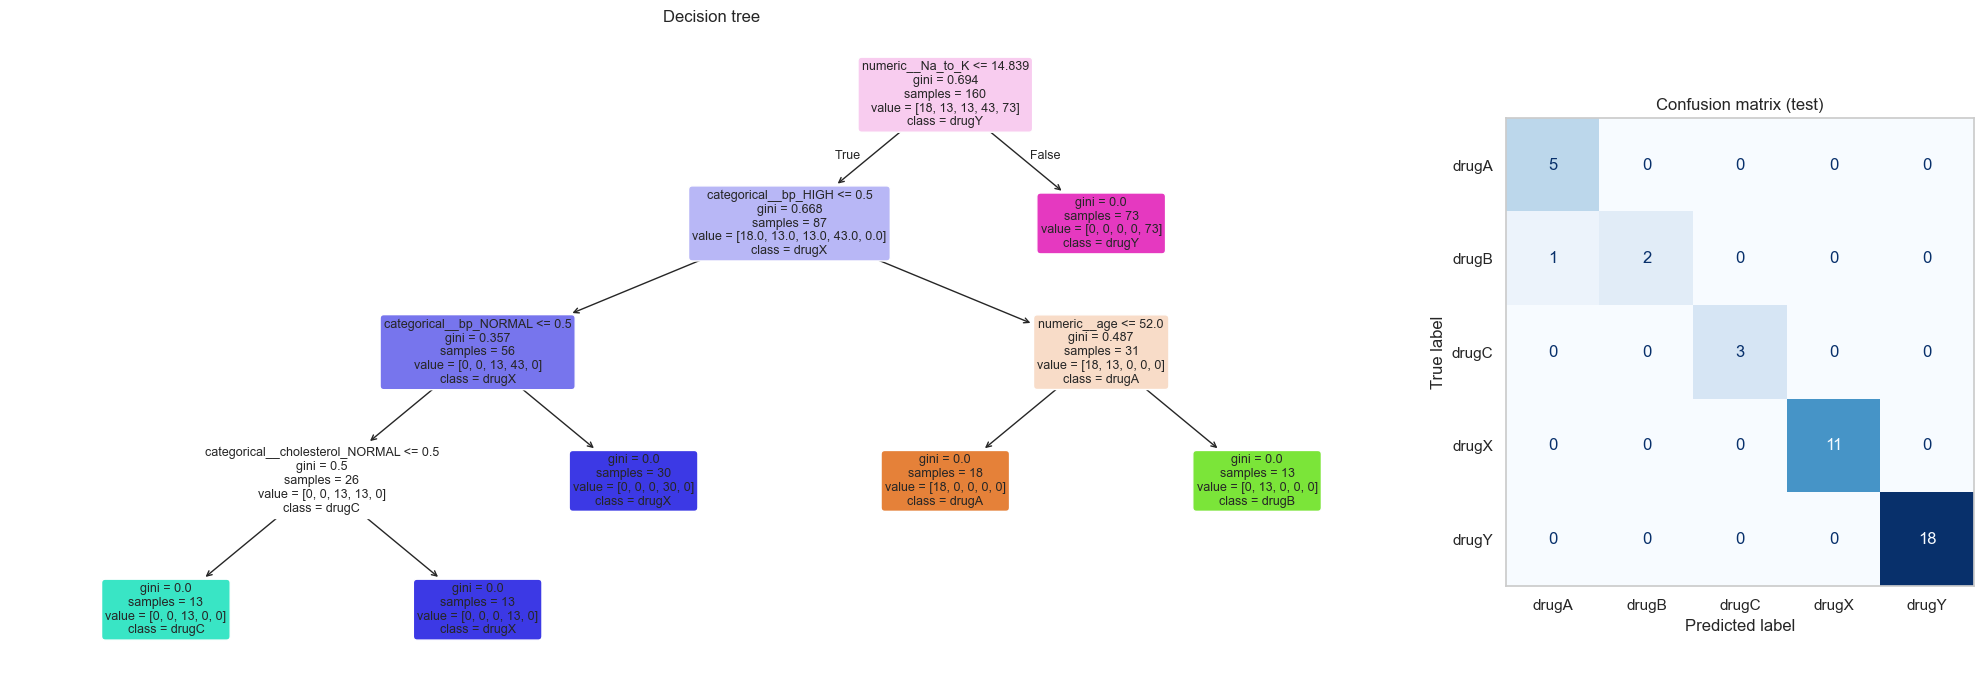

Predictions for new patients:
   age sex      bp cholesterol  Na_to_K predicted_drug
0   30   F    HIGH      NORMAL     12.0          drugA
1   60   M     LOW        HIGH      9.5          drugC
2   45   M  NORMAL        HIGH     27.0          drugY


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['drugA','drugB','drugC','drugX','drugY']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['age','sex','bp','cholesterol','Na_to_K']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [9]:
DRUG_NUMERIC = ['age', 'Na_to_K']
DRUG_CATEGORICAL = ['sex', 'bp', 'cholesterol']


def additional(data):
    """
    Predict which drug suits a patient (resources/drug.csv) with a decision tree:
    the data has a few clear thresholds (e.g. Na_to_K), which a tree captures and explains well.

    Args:
        data: drug data.

    Returns:
        Pipeline: the fitted model.
    """
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    data['drug'].value_counts().plot.bar(ax=axes[0], color='tab:purple', title='Drug distribution')
    sns.boxplot(data=data, x='drug', y='Na_to_K', ax=axes[1]).set_title('Na_to_K by drug')
    sns.countplot(data=data, x='bp', hue='drug', ax=axes[2]).set_title('Blood pressure by drug')
    save_figure(fig, 'drug_overview.png')

    X, y = data.drop(columns='drug'), data['drug']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

    pipeline = Pipeline([
        ('preprocess', ColumnTransformer([
            ('categorical', OneHotEncoder(handle_unknown='ignore'), DRUG_CATEGORICAL),
            ('numeric', 'passthrough', DRUG_NUMERIC),  # trees do not need scaling
        ])),
        ('model', DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ])
    search = GridSearchCV(pipeline, {'model__max_depth': [2, 3, 4, 5, 6], 'model__min_samples_leaf': [1, 3, 5]},
                          cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), scoring='f1_macro')
    model = search.fit(X_train, y_train).best_estimator_
    print(f'Best params: {search.best_params_}, CV macro F1 = {search.best_score_:.3f}')
    print(classification_report(y_test, model.predict(X_test)))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={'width_ratios': [3, 1]})
    plot_tree(model[-1], feature_names=model[:-1].get_feature_names_out(), class_names=model[-1].classes_,
              filled=True, rounded=True, fontsize=9, ax=ax1)
    ax1.set_title('Decision tree')
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues', ax=ax2, colorbar=False)
    ax2.set_title('Confusion matrix (test)')
    ax2.grid(False)
    save_figure(fig, 'drug_decision_tree.png')

    new_patients = pd.DataFrame([
        {'age': 30, 'sex': 'F', 'bp': 'HIGH', 'cholesterol': 'NORMAL', 'Na_to_K': 12.0},
        {'age': 60, 'sex': 'M', 'bp': 'LOW', 'cholesterol': 'HIGH', 'Na_to_K': 9.5},
        {'age': 45, 'sex': 'M', 'bp': 'NORMAL', 'cholesterol': 'HIGH', 'Na_to_K': 27.0},
    ])
    print('Predictions for new patients:')
    print(new_patients.assign(predicted_drug=model.predict(new_patients)))
    return model

data = extract_texts_from_file('resources/drug.csv')
additional(data)

## Machine learning analysis on texts

Predict text score (sentiment, holistic score, etc., any other target label) using machine learning algorithm you see best fit for the task. Choose kaggle dataset from available below. Display classification report (confusion matrix, accuracy, f1 score, etc.). 

- Learning Agency Lab - Automated Essay Scoring 2.0: predict holistic text score given full_text (student essays) https://www.kaggle.com/competitions/learning-agency-lab-automated-essay-scoring-2
- 100K Coursera's Course Reviews Dataset: predict the final rating (1 to 5) based on the text of the review https://www.kaggle.com/datasets/septa97/100k-courseras-course-reviews-dataset
- LLM - Detect AI Generated Text: predict the target label (0 being written by student and 1 being written by LLM) given the full text https://www.kaggle.com/competitions/llm-detect-ai-generated-text
- 42K+ Udemy Course Enrollment Information Dataset🔥: classify course categories using Title and Summary; compare text-only features against combined title-and-summary features https://www.kaggle.com/datasets/songseungwon/2020-udemy-courses-dataset
- TMDB 5000 Movie Dataset: movie classification based on description https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata?select=tmdb_5000_movies.csv



C:\Users\CoreUltra\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100038 unique reviews; label distribution:
Label
1    0.024
2    0.022
3    0.050
4    0.173
5    0.731
Name: proportion, dtype: float64
Baseline (always 5): accuracy = 0.731, macro F1 = 0.169


Best params: {'model__C': 1}, CV macro F1 = 0.452


Test accuracy: 0.708
Test macro F1: 0.464
Test MAE (stars): 0.364
              precision    recall  f1-score   support

           1       0.40      0.57      0.47       480
           2       0.23      0.29      0.26       441
           3       0.28      0.41      0.33       996
           4       0.37      0.46      0.41      3463
           5       0.91      0.80      0.85     14628

    accuracy                           0.71     20008
   macro avg       0.44      0.51      0.46     20008
weighted avg       0.76      0.71      0.73     20008



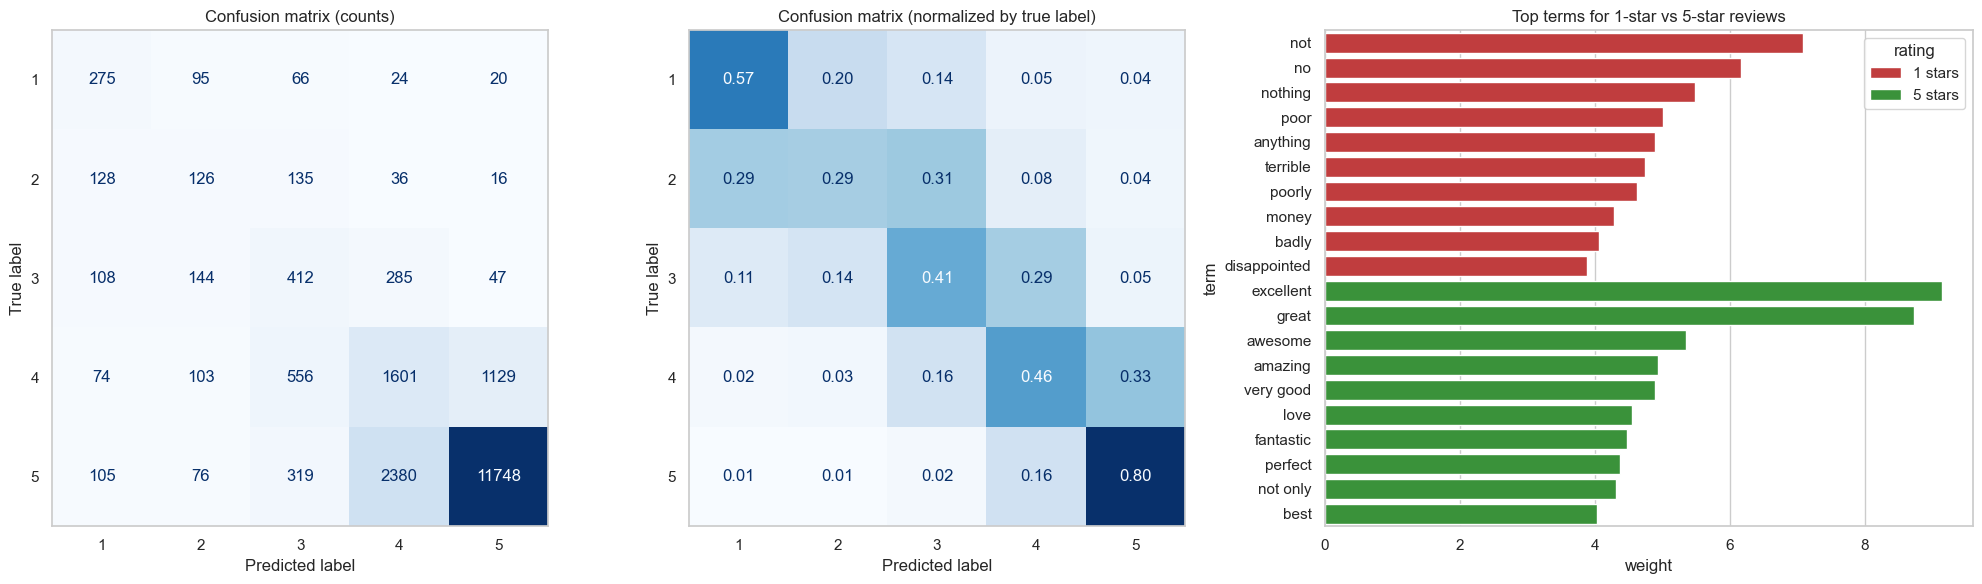

In [10]:
# pip install "kagglehub[pandas-datasets]"

import kagglehub
from kagglehub import KaggleDatasetAdapter

# If loading dataset via kaggle package fails (some of these do right now when I try because of encoding issues),
# donwload the dataset manually from webpage and place csv file(s) in the resources folder.
def load_dataset(url, csv_file):
    """
    Load the dataset from Kaggle using kagglehub.

    Args:
        url (str): The URL of the Kaggle dataset.
        csv_file (str): The name of the CSV file to load from the dataset.
    Returns:
        pd.DataFrame: The loaded dataset as a pandas DataFrame.
    """
    try:
        return kagglehub.dataset_load(KaggleDatasetAdapter.PANDAS, url, csv_file)
    except Exception as error:  # single-file download may fail the checksum check
        print(f'dataset_load failed ({type(error).__name__}), downloading the whole dataset instead')
        return pd.read_csv(Path(kagglehub.dataset_download(url)) / csv_file)

def classify_text_ml(df, text_column='Review', label_column='Label'):
    """
    Classify text data using a machine learning model.

    TF-IDF over word uni- and bigrams + logistic regression. Ratings are heavily skewed
    towards 5 stars, so the split is stratified, classes are re-weighted and the model is
    tuned and judged by macro F1 (accuracy alone would reward always predicting 5).

    Args:
        df (pd.DataFrame): The input DataFrame containing text data.
        text_column (str): Column with the review text.
        label_column (str): Column with the target rating.

    Returns:
        Pipeline: the fitted model.
    """
    df = df.dropna(subset=[text_column, label_column]).drop_duplicates(subset=[text_column])
    print(f'{len(df)} unique reviews; label distribution:')
    print(df[label_column].value_counts(normalize=True).sort_index().round(3))

    X_train, X_test, y_train, y_test = train_test_split(
        df[text_column], df[label_column], test_size=0.2, stratify=df[label_column], random_state=RANDOM_STATE)

    baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
    baseline_pred = baseline.predict(X_test)
    print(f'Baseline (always {baseline.classes_[np.argmax(baseline.class_prior_)]}): '
          f'accuracy = {accuracy_score(y_test, baseline_pred):.3f}, macro F1 = {f1_score(y_test, baseline_pred, average="macro"):.3f}')

    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True, strip_accents='unicode')),
        ('model', LogisticRegression(class_weight='balanced', max_iter=2000)),
    ])
    search = GridSearchCV(pipeline, {'model__C': [0.3, 1, 3]}, scoring='f1_macro',
                          cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE))
    model = search.fit(X_train, y_train).best_estimator_
    print(f'Best params: {search.best_params_}, CV macro F1 = {search.best_score_:.3f}')

    y_pred = model.predict(X_test)
    print(f'Test accuracy: {accuracy_score(y_test, y_pred):.3f}')
    print(f'Test macro F1: {f1_score(y_test, y_pred, average="macro"):.3f}')
    print(f'Test MAE (stars): {mean_absolute_error(y_test, y_pred):.3f}')
    print(classification_report(y_test, y_pred))

    fig, axes = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={'width_ratios': [1, 1, 1.3]})
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=axes[0], colorbar=False)
    axes[0].set_title('Confusion matrix (counts)')
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize='true', values_format='.2f', cmap='Blues', ax=axes[1], colorbar=False)
    axes[1].set_title('Confusion matrix (normalized by true label)')
    for ax in axes[:2]:
        ax.grid(False)

    # Most indicative words for the lowest and the highest rating.
    vocabulary = model['tfidf'].get_feature_names_out()
    classes = list(model['model'].classes_)
    top = []
    for label in (classes[0], classes[-1]):
        weights = pd.Series(model['model'].coef_[classes.index(label)], index=vocabulary).nlargest(10)
        top.append(pd.DataFrame({'term': weights.index, 'weight': weights.values, 'rating': f'{label} stars'}))
    sns.barplot(data=pd.concat(top), x='weight', y='term', hue='rating', palette=['tab:red', 'tab:green'], ax=axes[2], dodge=False)
    axes[2].set_title(f'Top terms for {classes[0]}-star vs {classes[-1]}-star reviews')
    save_figure(fig, 'coursera_reviews_classification.png')

    return model

df = load_dataset('septa97/100k-courseras-course-reviews-dataset', 'reviews.csv')
model = classify_text_ml(df)